# EDA TDLF2026

**Configuración**

In [39]:
from pathlib import Path
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RAW = Path("../data/raw")
DROP = {"created_at", "age", "stage", "played_at", "picture"}

**Carga de datos**

In [40]:
def load(name):
    df = pd.read_csv(RAW / f"{name}_rows.csv", sep=None, engine="python")
    df.columns = df.columns.str.strip()
    df = df.drop(columns=[c for c in df.columns if c in DROP])
    for col in df.select_dtypes("object"):
        df[col] = df[col].str.strip()
    return df

groups     = load("groups")
categories = load("categories")
players    = load("players")
doubles    = load("doubles")
matches    = load("matches")

tables = {
    "groups": groups, "categories": categories, "players": players,
    "doubles": doubles, "matches": matches,
}

C:\Users\juan_\AppData\Local\Temp\ipykernel_8360\393426668.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):
C:\Users\juan_\AppData\Local\Temp\ipykernel_8360\393426668.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.

In [41]:
groups.head()

,id,name,category_id
0,1e6b3e68-8421-4f67-b398-c1ce51ad157b,Grupo A,4c93168b-5424-4855-abba-72878f52b76c
1,3131492b-8941-4e68-a7e7-4b6b7d0f1cdb,Grupo D,4c93168b-5424-4855-abba-72878f52b76c
2,589c525f-6fff-43c8-90d5-ce469d1d9b36,Grupo G,4c93168b-5424-4855-abba-72878f52b76c
3,5e6726f5-70d4-4d9b-ae06-84c638245697,Grupo B,5d748e43-d079-43b1-a359-f26adfd14d37
4,80b6d026-a3d7-40cf-bb03-9da04a2ab229,Grupo B,4c93168b-5424-4855-abba-72878f52b76c


**Inspección general**

In [42]:
for name, df in tables.items():
    print(f"\n=== {name} {df.shape} ===")
    print(df.dtypes.to_string())
    print("nulos:", df.isna().sum()[lambda s: s > 0].to_dict())
    print("filas duplicadas:", df.duplicated().sum(),
          "| ids duplicados:", df["id"].duplicated().sum())
    display(df.head(3))


=== groups (12, 3) ===
id             str
name           str
category_id    str
nulos: {}
filas duplicadas: 0 | ids duplicados: 0


,id,name,category_id
0,1e6b3e68-8421-4f67-b398-c1ce51ad157b,Grupo A,4c93168b-5424-4855-abba-72878f52b76c
1,3131492b-8941-4e68-a7e7-4b6b7d0f1cdb,Grupo D,4c93168b-5424-4855-abba-72878f52b76c
2,589c525f-6fff-43c8-90d5-ce469d1d9b36,Grupo G,4c93168b-5424-4855-abba-72878f52b76c



=== categories (2, 3) ===
id             str
name           str
description    str
nulos: {}
filas duplicadas: 0 | ids duplicados: 0


,id,name,description
0,4c93168b-5424-4855-abba-72878f52b76c,libre,"Abierta a todo jugador, sin importar edad o ni..."
1,5d748e43-d079-43b1-a359-f26adfd14d37,masters,Solo hombres de 50 años o más.



=== players (88, 3) ===
id      str
name    str
city    str
nulos: {'city': 2}
filas duplicadas: 0 | ids duplicados: 0


,id,name,city
0,051b9784-fd77-49af-b229-510cff66e6a7,Moises Miranda,Apaseo
1,05cb1c12-19f6-49f0-b4d8-ac6832e46b79,Ivan Guzman,Moroleon
2,0845ccd2-aae9-46db-9bef-97a38700b761,Ivan Zuñiga,Irapuato



=== doubles (44, 5) ===
id             str
category_id    str
group_id       str
player1_id     str
player2_id     str
nulos: {}
filas duplicadas: 0 | ids duplicados: 0


,id,category_id,group_id,player1_id,player2_id
0,07e18c4b-0c9c-48e7-b637-a9e7fc91a271,4c93168b-5424-4855-abba-72878f52b76c,d99ed6d7-7b65-4c93-9adb-9847905987b5,11d1d283-8977-4083-b596-69aabe4321b1,ed311e65-4431-47a5-b600-4f3ab705973c
1,097713e4-ce10-44f3-b3f5-6a92d2024936,4c93168b-5424-4855-abba-72878f52b76c,870bdb24-cf67-4208-8d20-066e4e378e3f,3b2e8109-3545-4129-a624-d6a886aa3f65,6441dc3a-8ee6-42de-a04c-35132c918320
2,0c5d6e05-5d0e-4ab3-8d5d-985ec4169eab,4c93168b-5424-4855-abba-72878f52b76c,870bdb24-cf67-4208-8d20-066e4e378e3f,05cb1c12-19f6-49f0-b4d8-ac6832e46b79,ecd724c8-0232-4786-95c5-0491838fce1f



=== matches (60, 7) ===
id                    str
group_id              str
double1_id            str
double2_id            str
score1              int64
score2              int64
winner_double_id      str
nulos: {}
filas duplicadas: 0 | ids duplicados: 0


,id,group_id,double1_id,double2_id,score1,score2,winner_double_id
0,00333fee-e45c-41f5-bd10-9d46016820ae,1e6b3e68-8421-4f67-b398-c1ce51ad157b,1d4d1683-9a3c-47e5-ad41-3978cb2d7712,513df05a-e0a8-46d8-a7c0-73715e230c97,4,10,513df05a-e0a8-46d8-a7c0-73715e230c97
1,01c7da70-5317-4752-8ef6-6496c7f6580e,80b6d026-a3d7-40cf-bb03-9da04a2ab229,0d4a988f-9bef-4f3a-85e1-18edf7b1a86e,e8574882-fdf9-43fa-8f65-e35bb00387a5,2,10,e8574882-fdf9-43fa-8f65-e35bb00387a5
2,02e42232-f234-4da9-9d5a-7a470706f066,1e6b3e68-8421-4f67-b398-c1ce51ad157b,1d4d1683-9a3c-47e5-ad41-3978cb2d7712,468a63ea-efdf-48fc-b599-b3fe9465b96f,7,10,468a63ea-efdf-48fc-b599-b3fe9465b96f


In [43]:
print(matches[["score1", "score2"]].describe())
print("\nPartidos por grupo:\n", matches["group_id"].value_counts().to_string())
print("\nParejas por categoría:\n", doubles["category_id"].value_counts().to_string())
print("\nCiudades distintas:", players["city"].nunique())

          score1     score2
count  60.000000  60.000000
mean    6.650000   6.333333
std     3.353849   3.592208
min     0.000000   0.000000
25%     4.000000   4.000000
50%     7.500000   7.000000
75%    10.000000  10.000000
max    10.000000  10.000000

Partidos por grupo:
 group_id
1e6b3e68-8421-4f67-b398-c1ce51ad157b    6
80b6d026-a3d7-40cf-bb03-9da04a2ab229    6
870bdb24-cf67-4208-8d20-066e4e378e3f    6
3131492b-8941-4e68-a7e7-4b6b7d0f1cdb    6
589c525f-6fff-43c8-90d5-ce469d1d9b36    6
d99ed6d7-7b65-4c93-9adb-9847905987b5    6
d0b59773-db79-4406-90ad-c27729b8d517    6
83e758ee-bbd5-484f-8464-5c43c4432832    6
80ba7f5c-985b-4d8a-98f7-d7daf9ca1637    3
5e6726f5-70d4-4d9b-ae06-84c638245697    3
f5494b22-9654-4182-b30f-bc15d8414baf    3
d545b6bf-bda9-4dee-a864-1dcc8e6901e6    3

Parejas por categoría:
 category_id
4c93168b-5424-4855-abba-72878f52b76c    32
5d748e43-d079-43b1-a359-f26adfd14d37    12

Ciudades distintas: 15


### Paso 2: validar llaves, consistencia y partidos por pareja

**Celda 5: llaves foráneas y jugadores**

In [44]:
def check_fk(child, col, parent, label):
    print(f"{label}: {(~child[col].isin(parent['id'])).sum()} huérfanos")

check_fk(groups,  "category_id",      categories, "groups -> categories")
check_fk(doubles, "category_id",      categories, "doubles -> categories")
check_fk(doubles, "group_id",         groups,     "doubles -> groups")
check_fk(doubles, "player1_id",       players,    "doubles -> players (j1)")
check_fk(doubles, "player2_id",       players,    "doubles -> players (j2)")
check_fk(matches, "group_id",         groups,     "matches -> groups")
check_fk(matches, "double1_id",       doubles,    "matches -> doubles (1)")
check_fk(matches, "double2_id",       doubles,    "matches -> doubles (2)")
check_fk(matches, "winner_double_id", doubles,    "winner -> doubles")

in_pairs = pd.concat([doubles["player1_id"], doubles["player2_id"]])
print("\njugadores repetidos en más de una pareja:", in_pairs.duplicated().sum())
print("jugadores sin pareja:", (~players["id"].isin(in_pairs)).sum())

groups -> categories: 0 huérfanos
doubles -> categories: 0 huérfanos
doubles -> groups: 0 huérfanos
doubles -> players (j1): 0 huérfanos
doubles -> players (j2): 0 huérfanos
matches -> groups: 0 huérfanos
matches -> doubles (1): 0 huérfanos
matches -> doubles (2): 0 huérfanos
winner -> doubles: 0 huérfanos

jugadores repetidos en más de una pareja: 0
jugadores sin pareja: 0


**Celda 6: consistencia de los partidos**

In [45]:
g = doubles[["id", "group_id"]]
m = (matches
     .merge(g.rename(columns={"id": "double1_id", "group_id": "g1"}), on="double1_id")
     .merge(g.rename(columns={"id": "double2_id", "group_id": "g2"}), on="double2_id"))

print("parejas de otro grupo:", ((m.g1 != m.group_id) | (m.g2 != m.group_id)).sum())
print("empates en marcador:", (m.score1 == m.score2).sum())
print("ganador que no jugó el partido:",
      (~((m.winner_double_id == m.double1_id) | (m.winner_double_id == m.double2_id))).sum())

esperado = np.where(m.score1 > m.score2, m.double1_id,
                    np.where(m.score2 > m.score1, m.double2_id, None))
print("ganador distinto al marcador:", (m.winner_double_id != esperado).sum())

llave = m[["double1_id", "double2_id"]].apply(lambda r: tuple(sorted(r)), axis=1)
print("enfrentamientos repetidos:", llave.duplicated().sum())

parejas de otro grupo: 0
empates en marcador: 0
ganador que no jugó el partido: 0
ganador distinto al marcador: 0
enfrentamientos repetidos: 0


**Celda 7: tabla larga (una fila por pareja y partido) y partidos por pareja**

In [46]:
cols = ["id", "group_id", "winner_double_id"]
a = matches[cols + ["double1_id", "score1", "score2"]].rename(
    columns={"double1_id": "double_id", "score1": "pf", "score2": "pc"})
b = matches[cols + ["double2_id", "score2", "score1"]].rename(
    columns={"double2_id": "double_id", "score2": "pf", "score1": "pc"})

long = pd.concat([a, b], ignore_index=True).rename(columns={"id": "match_id"})
long["gano"] = (long["double_id"] == long["winner_double_id"]).astype(int)
long["diff"] = long["pf"] - long["pc"]
long["por_tiempo"] = long[["pf", "pc"]].max(axis=1) < 10

pj = long.groupby("double_id").size().rename("pj")
cat_name = categories.set_index("id")["name"].rename("categoria")
d = doubles.set_index("id").join(pj).join(cat_name, on="category_id")

print(d.groupby("categoria")["pj"].value_counts(dropna=False).unstack(fill_value=0))
print("\nPartidos por tiempo (por categoría):")
print(long.drop_duplicates("match_id")
          .merge(groups[["id", "category_id"]], left_on="group_id", right_on="id")
          .merge(cat_name, left_on="category_id", right_index=True)
          .groupby("categoria")["por_tiempo"].agg(["sum", "count"]))

pj          3   2
categoria        
libre      32   0
masters     0  12

Partidos por tiempo (por categoría):
           sum  count
categoria            
libre        9     48
masters      5     12


**Celda 8: ciudades**

In [47]:
print(players["city"].value_counts(dropna=False).to_string())

sin_ciudad = players.loc[players["city"].isna(), "id"]
print("\nParejas con un jugador sin ciudad:")
print(doubles[doubles["player1_id"].isin(sin_ciudad) | doubles["player2_id"].isin(sin_ciudad)])

city
Irapuato          27
Moroleon          12
Morelia            8
Apaseo             7
Queretaro          7
Celaya             6
Cortazar           5
cdmx               4
Aculco             3
NaN                2
Penjamo            2
Xalapa             1
Jilotepec          1
Salamanca          1
Toluca             1
Tepeji del rio     1

Parejas con un jugador sin ciudad:
                                      id                           category_id                              group_id                            player1_id                            player2_id
31  c70f4c58-f9d2-4d08-927a-9f01c4207b9e  5d748e43-d079-43b1-a359-f26adfd14d37  d545b6bf-bda9-4dee-a864-1dcc8e6901e6  228088df-42ab-42c7-9e64-9c012f227359  7325f6cc-e3dc-4c8a-8907-035453173ae7


In [48]:
pn = players.set_index("id")
dd0 = doubles.copy()
dd0["pareja"] = dd0["player1_id"].map(pn["name"]) + " / " + dd0["player2_id"].map(pn["name"])

# Parejas que perdieron por default (confirmado con el organizador)
WO_PAREJAS = [
    "PD1-1 / PD1-2",
    "Aluche partner / Aluche",
    "Issac Flores / Elliot Becerril",
]
wo_ids = set(dd0.loc[dd0["pareja"].isin(WO_PAREJAS), "id"])
assert len(wo_ids) == 3, "revisa la escritura de los nombres en WO_PAREJAS"

# Compañeros que no dieron su nombre
mask = players["name"].str.contains("partner", case=False, na=False)
print(players.loc[mask, "name"].tolist())
players.loc[mask, "name"] = "Compañero"

['Abraham partner', 'Aluche partner']


**celda 9: importar y armar la tabla de parejas:**

In [49]:
import sys
sys.path.append("..")
%load_ext autoreload
%autoreload 2
from src.sinergy import sinergia

wo_matches = set(long.loc[long["double_id"].isin(wo_ids), "match_id"])
assert len(wo_matches) == 7, f"se esperaban 7 partidos por default, hay {len(wo_matches)}"
long["wo"] = long["match_id"].isin(wo_matches)

real = long[~long["wo"]]

pairs = (real.groupby("double_id")
         .agg(pj=("match_id", "count"), pg=("gano", "sum"),
              pf=("pf", "sum"), pc=("pc", "sum"),
              n_tiempo=("por_tiempo", "sum"))
         .reset_index())

# Victorias oficiales (incluyen las ganadas por default) para la tabla de grupo
oficial = (long.groupby("double_id")
           .agg(pj_of=("match_id", "count"), pg_of=("gano", "sum"))
           .reset_index())
wo_ganados = (long[long["wo"] & (long["gano"] == 1)]
              .groupby("double_id").size().rename("wo_ganados").reset_index())

pairs = (pairs.merge(oficial, on="double_id", how="left")
              .merge(wo_ganados, on="double_id", how="left"))
pairs["wo_ganados"] = pairs["wo_ganados"].fillna(0).astype(int)

pairs["dif"]        = pairs["pf"] - pairs["pc"]
pairs["pf_pp"]      = pairs["pf"] / pairs["pj"]
pairs["pc_pp"]      = pairs["pc"] / pairs["pj"]
pairs["pct_puntos"] = pairs["pf"] / (pairs["pf"] + pairs["pc"])
pairs["sinergia"]   = sinergia(pairs["pf"], pairs["pc"], pairs["pj"])

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**Celda 10: pegar nombres, ciudades, grupo y categoría**

In [50]:
pn = players.set_index("id")

dd = doubles.copy()
dd["j1"] = dd["player1_id"].map(pn["name"])
dd["j2"] = dd["player2_id"].map(pn["name"])
dd["pareja"]  = dd["j1"] + " / " + dd["j2"]
dd["ciudad1"] = dd["player1_id"].map(pn["city"])
dd["ciudad2"] = dd["player2_id"].map(pn["city"])

pairs = (pairs
         .merge(dd.rename(columns={"id": "double_id"}), on="double_id")
         .merge(cat_name, left_on="category_id", right_index=True)
         .merge(groups[["id", "name"]].rename(columns={"id": "group_id", "name": "grupo"}),
                on="group_id"))
pairs_wo = dd[dd["id"].isin(wo_ids)][["id", "pareja", "ciudad1", "ciudad2"]]

In [51]:
pairs.head()

,double_id,pj,pg,pf,pc,n_tiempo,pj_of,pg_of,wo_ganados,dif,pf_pp,pc_pp,pct_puntos,sinergia,category_id,group_id,player1_id,player2_id,j1,j2,pareja,ciudad1,ciudad2,categoria,grupo
0,07e18c4b-0c9c-48e7-b637-a9e7fc91a271,3,2,23,22,0,3,2,0,1,7.666667,7.333333,0.511111,12.121212,4c93168b-5424-4855-abba-72878f52b76c,d99ed6d7-7b65-4c93-9adb-9847905987b5,11d1d283-8977-4083-b596-69aabe4321b1,ed311e65-4431-47a5-b600-4f3ab705973c,Tiburon,Wicho,Tiburon / Wicho,Moroleon,Moroleon,libre,Grupo F
1,097713e4-ce10-44f3-b3f5-6a92d2024936,3,1,18,26,0,3,1,0,-8,6.000000,8.666667,0.409091,-15.151515,4c93168b-5424-4855-abba-72878f52b76c,870bdb24-cf67-4208-8d20-066e4e378e3f,3b2e8109-3545-4129-a624-d6a886aa3f65,6441dc3a-8ee6-42de-a04c-35132c918320,Diego Solis,Francisco Solis,Diego Solis / Francisco Solis,Irapuato,Irapuato,libre,Grupo E
2,0c5d6e05-5d0e-4ab3-8d5d-985ec4169eab,3,2,24,19,1,3,2,0,5,8.000000,6.333333,0.558140,24.242424,4c93168b-5424-4855-abba-72878f52b76c,870bdb24-cf67-4208-8d20-066e4e378e3f,05cb1c12-19f6-49f0-b4d8-ac6832e46b79,ecd724c8-0232-4786-95c5-0491838fce1f,Ivan Guzman,Luis Zavala,Ivan Guzman / Luis Zavala,Moroleon,Moroleon,libre,Grupo E
3,0d4a988f-9bef-4f3a-85e1-18edf7b1a86e,3,1,13,27,0,3,1,0,-14,4.333333,9.000000,0.325000,-33.333333,4c93168b-5424-4855-abba-72878f52b76c,80b6d026-a3d7-40cf-bb03-9da04a2ab229,895929c2-88d2-439d-8a00-3e8c44960dfe,e99d9f90-dfc8-4ad7-a4ba-deb1eaa8ca4d,Flako Arroyo,Moroco,Flako Arroyo / Moroco,Cortazar,Cortazar,libre,Grupo B
4,1d4d1683-9a3c-47e5-ad41-3978cb2d7712,3,0,19,30,0,3,0,0,-11,6.333333,10.000000,0.387755,-24.242424,4c93168b-5424-4855-abba-72878f52b76c,1e6b3e68-8421-4f67-b398-c1ce51ad157b,52d269df-d20b-486e-b104-fdd08a25d2f4,e14db121-efe5-4ff9-abb8-cda63d4c5a9c,Luis Espitia,Adrian Arreola,Luis Espitia / Adrian Arreola,Penjamo,Penjamo,libre,Grupo A


**Celda 11: ranking por categoría.**

In [52]:
cols = ["grupo", "pareja", "pj", "pg", "wo_ganados", "pf", "pc", "dif",
        "pct_puntos", "sinergia", "n_tiempo"]

for cat, df in pairs.groupby("categoria"):
    print(f"\n=== {cat} ===")
    display(df.sort_values("sinergia", ascending=False)[cols].round(2).reset_index(drop=True))


=== libre ===


,grupo,pareja,pj,pg,wo_ganados,pf,pc,dif,pct_puntos,sinergia,n_tiempo
0,Grupo C,Hugo Arizmendi / Mario Escamilla,2,2,1,20,6,14,0.77,72.73,0
1,Grupo F,Avimael Tapia / Lenin Bustos,3,3,0,30,9,21,0.77,72.73,0
2,Grupo D,Santiago Mtz / Gerardo Macizo,3,3,0,30,10,20,0.75,69.70,0
3,Grupo G,Julio Mendez / Miguel Baez,3,3,0,30,11,19,0.73,66.67,0
4,Grupo B,Marco Rodriguez / Josue Gomez,3,3,0,29,11,18,0.72,63.64,1
5,Grupo B,Jorge Isaac / Ivan Zamora,3,2,0,28,10,18,0.74,63.64,1
6,Grupo H,Carlos Machado / Oscar Gallegos,3,3,0,30,14,16,0.68,57.58,0
7,Grupo E,Enrique Lara / Gerardo Cruz,3,3,0,29,14,15,0.67,54.55,1
8,Grupo A,Chicaro / Daniel Detec,3,3,0,30,17,13,0.64,48.48,0
9,Grupo H,Lenin Reyes / Ricardo Rodriguez,3,2,0,25,15,10,0.62,39.39,0



=== masters ===


,grupo,pareja,pj,pg,wo_ganados,pf,pc,dif,pct_puntos,sinergia,n_tiempo
0,Grupo A,Macoy / Jorge Gutierrez,1,1,1,10,4,6,0.71,63.64,0
1,Grupo C,Fernando / Wuicho,2,2,0,18,9,9,0.67,50.00,1
2,Grupo B,Marco Mtz / Humberto Mtz,2,2,0,20,11,9,0.65,50.00,0
3,Grupo B,Carlos Labra / Antonio T,2,1,0,17,12,5,0.59,31.82,0
4,Grupo D,Joaquin / Salvador,1,1,1,10,8,2,0.56,27.27,0
5,Grupo C,Jorge Zavala / Javier Zavala,2,1,0,15,16,-1,0.48,4.55,1
6,Grupo D,Mauricio Castillo / Refugio Castillo,1,0,1,8,10,-2,0.44,-9.09,0
7,Grupo C,Alfonso Vega / Cafe,2,0,0,12,20,-8,0.38,-27.27,0
8,Grupo A,Compañero / Abraham Aguiñiga,1,0,1,4,10,-6,0.29,-45.45,0
9,Grupo B,Alfredo Rocha / Luis Segura,2,0,0,6,20,-14,0.23,-54.55,0


In [53]:
print(pairs.groupby("categoria").size())                  # libre 31, masters 10
print(pairs.groupby("categoria")["pj"].sum() / 2)         # libre 45, masters 8 partidos reales
print(pairs.groupby("categoria")["pj"].value_counts().unstack(fill_value=0))

categoria
libre      31
masters    10
dtype: int64
categoria
libre      45.0
masters     8.0
Name: pj, dtype: float64
pj         1  2   3
categoria          
libre      0  3  28
masters    4  6   0


**Celda 12: lo que define premios y arquetipos**

In [54]:
for cat, df in pairs.groupby("categoria"):
    print(f"\n=== {cat} ===")
    print(df[["pf_pp", "pc_pp", "dif", "pct_puntos", "sinergia"]].describe().round(2))
    print("invictas:", (df["pg"] == df["pj"]).sum(),
          "| sin victorias:", (df["pg"] == 0).sum())
    print("correlación pf_pp vs pc_pp:", round(df["pf_pp"].corr(df["pc_pp"]), 2))


=== libre ===
       pf_pp  pc_pp   dif  pct_puntos  sinergia
count  31.00  31.00  31.0       31.00     31.00
mean    6.92   6.92   0.0        0.50      9.09
std     2.46   2.52  13.5        0.18     42.40
min     1.67   3.00 -22.0        0.20    -57.58
25%     5.17   4.67 -11.0        0.36    -25.76
50%     6.67   7.33  -2.0        0.48      3.03
75%     9.50   9.25  13.5        0.66     51.52
max    10.00  10.00  21.0        0.77     72.73
invictas: 8 | sin victorias: 8
correlación pf_pp vs pc_pp: -0.75

=== masters ===
       pf_pp  pc_pp    dif  pct_puntos  sinergia
count  10.00  10.00  10.00       10.00     10.00
mean    7.60   7.60   0.00        0.50      9.09
std     2.51   2.42   7.66        0.16     41.99
min     3.00   4.00 -14.00        0.23    -54.55
25%     6.38   5.62  -5.00        0.39    -22.73
50%     8.25   8.00   0.50        0.52     15.91
75%     9.75  10.00   5.75        0.63     45.45
max    10.00  10.00   9.00        0.71     63.64
invictas: 4 | sin victorias: 4

**Celda 13: tabla de partidos con nombres y bandera de default**

In [55]:
nombre = dd.set_index("id")["pareja"]

mt = (matches
      .merge(groups[["id", "name", "category_id"]]
             .rename(columns={"id": "group_id", "name": "grupo"}), on="group_id")
      .merge(cat_name, left_on="category_id", right_index=True))
mt["p1"] = mt["double1_id"].map(nombre)
mt["p2"] = mt["double2_id"].map(nombre)
mt["margen"] = (mt["score1"] - mt["score2"]).abs()
mt["total"] = mt["score1"] + mt["score2"]
mt["por_tiempo"] = mt[["score1", "score2"]].max(axis=1) < 10
mt["wo"] = mt["id"].isin(wo_matches)

**Celda 14: comprobar que la regla de default es limpia**

In [56]:
print("Marcadores de los partidos por default:")
print(mt.loc[mt["wo"], ["score1", "score2"]]
        .apply(lambda r: tuple(sorted(r)), axis=1).value_counts())

print("\nPartidos NO default donde alguien anotó 0:")
display(mt.loc[~mt["wo"] & (mt[["score1", "score2"]].min(axis=1) == 0),
               ["categoria", "grupo", "p1", "score1", "score2", "p2"]])

Marcadores de los partidos por default:
(0, 5)    7
Name: count, dtype: int64

Partidos NO default donde alguien anotó 0:


,categoria,grupo,p1,score1,score2,p2
25,libre,Grupo B,Jorge Isaac / Ivan Zamora,10,0,Valentin Guerrero / Martin Jimenez
44,libre,Grupo G,Emiliano Zavala / Efrain Rojas,5,0,Israel Lara / Rafael Becerril
54,libre,Grupo G,Mikjail Juarez / Ignacio Orozco,5,0,Israel Lara / Rafael Becerril


**Celda 15: jerarquía con victorias oficiales (incluyen las de default) y probabilidad corregida**

In [57]:
from math import factorial

of = (long.groupby("double_id").agg(pg_of=("gano", "sum")).reset_index()
      .merge(doubles[["id", "group_id"]], left_on="double_id", right_on="id")
      .merge(groups[["id", "name", "category_id"]]
             .rename(columns={"id": "group_id", "name": "grupo"}), on="group_id")
      .merge(cat_name, left_on="category_id", right_index=True))

wins = (of.groupby(["categoria", "grupo"])["pg_of"]
        .agg(lambda s: tuple(sorted(s, reverse=True))))
print(wins.to_string())

# libre: 7 grupos de 4 con partidos completos + el grupo C, que fue de 3 por el default
p4 = factorial(4) / 2 ** 6
p3 = factorial(3) / 2 ** 3
p = p4 ** 7 * p3
print(f"\nP(orden perfecto en libre) = {p:.5f} (alrededor de 1 en {1/p:,.0f})")

categoria  grupo  
libre      Grupo A    (3, 2, 1, 0)
           Grupo B    (3, 2, 1, 0)
           Grupo C    (3, 2, 1, 0)
           Grupo D    (3, 2, 1, 0)
           Grupo E    (3, 2, 1, 0)
           Grupo F    (3, 2, 1, 0)
           Grupo G    (3, 2, 1, 0)
           Grupo H    (3, 2, 1, 0)
masters    Grupo A       (2, 1, 0)
           Grupo B       (2, 1, 0)
           Grupo C       (2, 1, 0)
           Grupo D       (2, 1, 0)

P(orden perfecto en libre) = 0.00078 (alrededor de 1 en 1,279)


**Celda 16: significancia de la correlación**

In [58]:
from scipy import stats

for cat, df in pairs.groupby("categoria"):
    r, p = stats.pearsonr(df["pf_pp"], df["pc_pp"])
    print(f"{cat}: r={r:.3f}, p={p:.2e}, n={len(df)}")

libre: r=-0.754, p=9.53e-07, n=31
masters: r=-0.749, p=1.26e-02, n=10


**Celda 17: fuera de serie (solo partidos reales)**

In [59]:
mr = mt[~mt["wo"]]
cols_p = ["grupo", "p1", "score1", "score2", "p2", "por_tiempo"]

for cat, df in mr.groupby("categoria"):
    print(f"\n=== {cat}: {len(df)} partidos reales ===")
    print("Cardiacos (margen 1):", (df["margen"] == 1).sum(),
          "| por tiempo:", df["por_tiempo"].sum())
    print("\nMás cerrados (margen <= 1), de menor a mayor total de puntos:")
    display(df[df["margen"] <= 1].sort_values("total")[cols_p])
    print("Mayores palizas:")
    display(df.sort_values(["margen", "total"], ascending=[False, True]).head(5)[cols_p])


=== libre: 45 partidos reales ===
Cardiacos (margen 1): 3 | por tiempo: 6

Más cerrados (margen <= 1), de menor a mayor total de puntos:


,grupo,p1,score1,score2,p2,por_tiempo
46,Grupo A,Edgar Garcia / Luis Bravo,8,7,Juan Pablo / Owen Alexander,True
41,Grupo B,Jorge Isaac / Ivan Zamora,8,9,Marco Rodriguez / Josue Gomez,True
36,Grupo F,Daniel Ap / Alex Ap,9,10,Ignacio Acevedo / Edgar Labra,False


Mayores palizas:


,grupo,p1,score1,score2,p2,por_tiempo
25,Grupo B,Jorge Isaac / Ivan Zamora,10,0,Valentin Guerrero / Martin Jimenez,False
10,Grupo B,Flako Arroyo / Moroco,1,10,Jorge Isaac / Ivan Zamora,False
11,Grupo B,Valentin Guerrero / Martin Jimenez,1,10,Marco Rodriguez / Josue Gomez,False
29,Grupo D,Ivan Padron / Omar Melendez,1,10,Santiago Mtz / Gerardo Macizo,False
1,Grupo B,Flako Arroyo / Moroco,2,10,Marco Rodriguez / Josue Gomez,False



=== masters: 8 partidos reales ===
Cardiacos (margen 1): 0 | por tiempo: 1

Más cerrados (margen <= 1), de menor a mayor total de puntos:


,grupo,p1,score1,score2,p2,por_tiempo


Mayores palizas:


,grupo,p1,score1,score2,p2,por_tiempo
22,Grupo B,Carlos Labra / Antonio T,10,2,Alfredo Rocha / Luis Segura,False
6,Grupo C,Fernando / Wuicho,10,4,Alfonso Vega / Cafe,False
19,Grupo B,Marco Mtz / Humberto Mtz,10,4,Alfredo Rocha / Luis Segura,False
35,Grupo A,Macoy / Jorge Gutierrez,10,4,Compañero / Abraham Aguiñiga,False
42,Grupo C,Fernando / Wuicho,8,5,Jorge Zavala / Javier Zavala,True


**Celda 18: ritmo**: Si la correlación ritmo vs sinergia es baja, los dos ejes son independientes y sirven para separar estilos.

In [60]:
pairs["ritmo"] = pairs["pf_pp"] + pairs["pc_pp"]

for cat, df in pairs.groupby("categoria"):
    print(f"\n=== {cat} ===")
    print(df[["ritmo", "sinergia"]].describe().round(2))
    print("corr ritmo vs sinergia:", round(df["ritmo"].corr(df["sinergia"]), 2))


=== libre ===
       ritmo  sinergia
count  31.00     31.00
mean   13.85      9.09
std     1.75     42.40
min     8.33    -57.58
25%    13.33    -25.76
50%    14.00      3.03
75%    14.83     51.52
max    17.00     72.73
corr ritmo vs sinergia: -0.03

=== masters ===
       ritmo  sinergia
count  10.00     10.00
mean   15.20      9.09
std     1.75     41.99
min    13.00    -54.55
25%    14.00    -22.73
50%    15.00     15.91
75%    15.88     45.45
max    18.00     63.64
corr ritmo vs sinergia: 0.05


**Celda 19: constructor de slides**

In [61]:
from unidecode import unidecode

def slide(sid, tipo, titulo, texto, datos=None, categoria=None):
    return {"id": sid, "tipo": tipo, "categoria": categoria,
            "titulo": titulo, "texto": texto, "datos": datos or {}}

def ciudades_de(df):
    ids = pd.concat([df["player1_id"], df["player2_id"]])
    c = players.set_index("id").loc[ids, "city"].dropna()
    return c.map(lambda s: unidecode(s).strip().lower())

def s_apertura(cat):
    df = pairs[pairs["categoria"] == cat]
    n_parejas, n_partidos = len(df), int(df["pj"].sum() // 2)
    n_puntos, n_ciudades = int(df["pf"].sum()), ciudades_de(df).nunique()
    texto = (f"Llegaron de {n_ciudades} ciudades distintas, jugaron {n_partidos} partidos "
             f"y entre todos anotaron más de {n_puntos} puntos. Esta es su historia.")
    return slide("apertura", "stat", f"{n_parejas} parejas, un solo torneo", texto,
                 {"parejas": n_parejas, "partidos": n_partidos,
                  "puntos": n_puntos, "ciudades": n_ciudades}, cat)

def s_playmakers(cat):
    df = pairs[pairs["categoria"] == cat].copy()
    df["s"] = df["sinergia"].round(2)
    top = df[df["s"] == df["s"].max()].sort_values("pj", ascending=False)
    prom = round(df["sinergia"].mean(), 1)
    base = "Una pareja que ganara todos sus partidos 10-0 tendría 100% de sinergia. "
    if len(top) == 1:
        r = top.iloc[0]
        solo = " Lo logró en un solo partido." if r["pj"] == 1 else ""
        texto = (base + f"La más cercana fue {r['pareja']}: {int(r['pf'])} puntos a favor, "
                 f"{int(r['pc'])} en contra y {r['sinergia']:.1f}%.{solo} El promedio fue {prom}%.")
        titulo = "La sinergia más cercana a la perfección"
    else:
        nombres = " y ".join(top["pareja"])
        texto = (base + f"En la cima hubo un empate: {nombres}, con "
                 f"{top['sinergia'].iloc[0]:.1f}% cada una. El promedio fue {prom}%.")
        titulo = "Empate en la cima"
    ranking = (df.sort_values("sinergia", ascending=False).head(10)
               [["double_id", "pareja", "pj", "sinergia"]].round(2).to_dict("records"))
    return slide("playmakers", "ranking", titulo, texto,
                 {"promedio": prom, "ranking": ranking}, cat)

def s_perfectas(cat):
    df = pairs[(pairs["categoria"] == cat) & (pairs["pf"] == 10 * pairs["pj"])]
    if df.empty:
        return None
    mejor = (df[df["pc_pp"].round(2) == df["pc_pp"].round(2).min()]
             .sort_values("pj", ascending=False))
    nombres = " y ".join(
        f"{r['pareja']} ({int(r['pj'])} partido{'s' if r['pj'] > 1 else ''})"
        for _, r in mejor.iterrows())
    texto = (f"Ganaron todos sus partidos llegando siempre a 10 puntos. Para desempatar, cuenta quién "
             f"dejó menos puntos al rival: {nombres}, con {mejor['pc_pp'].iloc[0]:.1f} por partido.")
    return slide("a_diez", "stat", f"{len(df)} parejas siempre llegaron a 10", texto,
                 {"parejas": df["pareja"].tolist()}, cat)

# def s_ganar_no_es_dominar(cat):
#     df = pairs[pairs["categoria"] == cat]
#     mejor = None
#     for _, a in df.iterrows():
#         for _, b in df.iterrows():
#             if a["pj"] == b["pj"] and a["pg"] < b["pg"] and a["sinergia"] > b["sinergia"]:
#                 gap = a["sinergia"] - b["sinergia"]
#                 if mejor is None or gap > mejor[2]:
#                     mejor = (a, b, gap)
#     if mejor is None:
#         return None
#     a, b, _ = mejor
#     texto = (f"{a['pareja']} ganó {int(a['pg'])} partidos y {b['pareja']} ganó {int(b['pg'])}, "
#              f"pero {a['pareja']} tuvo más sinergia ({a['sinergia']:.1f}% contra "
#              f"{b['sinergia']:.1f}%). Importa cuánto ganas, no solo cuántas veces.")
#     return slide("ganar_no_es_dominar", "comparacion", "Más victorias, menos dominio",
#                  texto, {"a": a["double_id"], "b": b["double_id"]}, cat)

**Celda 20: Tema y gráficas**

In [62]:
import matplotlib.pyplot as plt
from scipy import stats

COL = {"fav": "#2a9d8f", "con": "#e76f51", "acento": "#e9c46a", "gris": "#8d99ae"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
UMBRAL_CARDIACO = 2

def etiqueta(df):
    return df["pareja"] + " (" + df["pj"].astype(str) + ")"

def par_ganar_no_es_dominar(cat):
    df = pairs[pairs["categoria"] == cat]
    df = df[df["pj"] == df["pj"].max()]
    mejor = None
    for _, a in df.iterrows():
        for _, b in df.iterrows():
            if a["pg"] < b["pg"] and a["sinergia"] > b["sinergia"]:
                gap = a["sinergia"] - b["sinergia"]
                if mejor is None or gap > mejor[2]:
                    mejor = (a, b, gap)
    return None if mejor is None else (mejor[0], mejor[1])

def top_infarto(cat, n=5):
    df = mr[mr["categoria"] == cat].sort_values(["margen", "total"]).head(n)
    filas = []
    for _, r in df.iterrows():
        g, sg, p, sp = ganador_perdedor(r)
        filas.append({"gano": g, "marcador": f"{sg}-{sp}", "perdio": p, "grupo": r["grupo"],
                      "margen": int(r["margen"]), "total": int(r["total"]),
                      "por_tiempo": bool(r["por_tiempo"])})
    return filas

def fig_pf_pc(cat):
    df = pairs[pairs["categoria"] == cat].sort_values("sinergia")
    fig, ax = plt.subplots(figsize=(10, 0.32 * len(df) + 1.5))
    y = np.arange(len(df))
    ax.barh(y, df["pf"], color=COL["fav"], label="Puntos a favor")
    ax.barh(y, -df["pc"], color=COL["con"], label="Puntos en contra")
    for yi, (a, b) in enumerate(zip(df["pf"], df["pc"])):
        ax.text(a + 0.4, yi, f"{int(a)}", va="center", ha="left",
                fontsize=8, fontweight="bold", color=COL["fav"])
        ax.text(-b - 0.4, yi, f"{int(b)}", va="center", ha="right",
                fontsize=8, fontweight="bold", color=COL["con"])
    ax.set_yticks(y)
    ax.set_yticklabels(etiqueta(df), fontsize=8)
    ax.axvline(0, color="black", lw=0.8)
    lo, hi = ax.get_xlim()
    ax.set_xlim(lo - 2, hi + 2)
    ax.xaxis.set_major_formatter(lambda v, _: f"{abs(int(v))}")
    ax.set_title(f"Puntos a favor y en contra por pareja ({cat})", loc="left", fontweight="bold")
    ax.set_xlabel("Entre paréntesis, partidos jugados")
    ax.legend(loc="lower right", frameon=False)
    plt.tight_layout()
    return fig

def fig_sinergia(cat):
    df = pairs[pairs["categoria"] == cat].sort_values("sinergia")
    fig, ax = plt.subplots(figsize=(10, 0.32 * len(df) + 1.5))
    y = np.arange(len(df))
    colores = np.where(df["sinergia"] >= 0, COL["fav"], COL["con"])
    ax.barh(y, df["sinergia"], color=colores)
    for yi, v in enumerate(df["sinergia"]):
        ax.text(v + (1.2 if v >= 0 else -1.2), yi, f"{v:.1f}%", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, fontweight="bold")
    prom = df["sinergia"].mean()
    ax.axvline(prom, color=COL["acento"], lw=2, ls="--")
    ax.text(prom, len(df) - 0.4, f" promedio {prom:.1f}%", va="bottom", fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels(etiqueta(df), fontsize=8)
    lo, hi = ax.get_xlim()
    ax.set_xlim(lo - 8, hi + 8)
    ax.set_title(f"Sinergia por pareja ({cat})", loc="left", fontweight="bold")
    ax.set_xlabel("Sinergia (%). Entre paréntesis, partidos jugados")
    plt.tight_layout()
    return fig

def fig_jerarquia(cat):
    d = of[of["categoria"] == cat]
    grupos = sorted(d["grupo"].unique())
    cols = min(4, len(grupos))
    filas = int(np.ceil(len(grupos) / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(3 * cols, 2.4 * filas), sharey=True)
    axs = np.atleast_1d(axs).ravel()
    ymax = d["pg_of"].max() + 0.7
    for ax, g in zip(axs, grupos):
        w = d[d["grupo"] == g]["pg_of"].sort_values(ascending=False).to_numpy()
        ax.bar(range(len(w)), w, color=COL["fav"])
        ax.bar_label(ax.containers[0], fontsize=8)
        ax.set_ylim(0, ymax)
        ax.set_title(g, fontsize=9)
        ax.set_xticks([])
    for ax in axs[len(grupos):]:
        ax.axis("off")
    esc = ", ".join(str(i) for i in range(len(w) - 1, -1, -1))
    fig.suptitle(f"{len(grupos)} grupos, la misma escalera: {esc} victorias ({cat})",
                 fontweight="bold")
    plt.tight_layout()
    return fig

def fig_ataque_defensa(cat):
    df = pairs[pairs["categoria"] == cat]
    r, _ = stats.pearsonr(df["pf_pp"], df["pc_pp"])
    m, b = np.polyfit(df["pf_pp"], df["pc_pp"], 1)
    x = np.linspace(df["pf_pp"].min(), df["pf_pp"].max(), 50)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.scatter(df["pf_pp"], df["pc_pp"], s=60, color=COL["fav"], alpha=0.85, edgecolor="white")
    ax.plot(x, m * x + b, color=COL["gris"], ls="--")
    ax.invert_yaxis()
    ax.set_xlabel("Puntos a favor por partido")
    ax.set_ylabel("Puntos en contra por partido (invertido)")
    ax.set_title(f"Atacar y defender ({cat})", loc="left", fontweight="bold")
    ax.text(0.03, 0.05, f"r = {r:.2f}  (n = {len(df)})", transform=ax.transAxes)
    ax.text(0.97, 0.03, "arriba a la derecha: anotan mucho y reciben poco",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=COL["gris"])
    plt.tight_layout()
    return fig

def fig_ganar_dominar(cat):
    df = pairs[pairs["categoria"] == cat].copy()
    df = df[df["pj"] == df["pj"].max()]
    rng = np.random.default_rng(7)
    df["x"] = df["pg"] + rng.uniform(-0.12, 0.12, len(df))
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.scatter(df["x"], df["sinergia"], s=55, color=COL["gris"], alpha=0.6, edgecolor="white")
    ax.axhline(df["sinergia"].mean(), color=COL["acento"], ls="--", lw=1)
    par = par_ganar_no_es_dominar(cat)
    if par is not None:
        a, b = par
        ax.axhline(a["sinergia"], color=COL["acento"], ls=":", lw=1.2)
        for fila, color, dx, ha in [(a, COL["acento"], -14, "right"), (b, COL["con"], 14, "left")]:
            x = df.loc[df["double_id"] == fila["double_id"], "x"].iloc[0]
            ax.scatter([x], [fila["sinergia"]], s=150, color=color, edgecolor="black", zorder=3)
            ax.annotate(f"{fila['pareja']}\n{int(fila['pg'])} victorias, {fila['sinergia']:.1f}%",
                        (x, fila["sinergia"]), xytext=(dx, 12), textcoords="offset points",
                        ha=ha, fontsize=8,
                        arrowprops={"arrowstyle": "-", "color": "black", "lw": 0.6})
    ax.set_xticks(sorted(df["pg"].unique()))
    ax.set_xlim(df["pg"].min() - 1.2, df["pg"].max() + 1.2)
    ax.set_xlabel("Victorias")
    ax.set_ylabel("Sinergia (%)")
    ax.set_title(f"Ganar no es dominar ({cat})", loc="left", fontweight="bold")
    plt.tight_layout()
    return fig

def fig_infarto(cat, n=5):
    filas = top_infarto(cat, n)
    celdas = [[f["gano"], f["marcador"], f["perdio"], f["grupo"],
               "sí" if f["por_tiempo"] else "no"] for f in filas]
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(celdas) + 1.4))
    ax.axis("off")
    tabla = ax.table(cellText=celdas, loc="center", cellLoc="left",
                     colLabels=["Ganó", "Marcador", "Perdió", "Grupo", "Por tiempo"])
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.auto_set_column_width(list(range(5)))
    tabla.scale(1, 1.6)
    for j in range(5):
        tabla[(0, j)].set_facecolor("#e9ecef")
        tabla[(0, j)].set_text_props(fontweight="bold")
    clave0 = (filas[0]["margen"], filas[0]["total"])
    for i, f in enumerate(filas, start=1):
        if (f["margen"], f["total"]) == clave0:
            for j in range(5):
                tabla[(i, j)].set_facecolor("#fff3c4")
                tabla[(i, j)].set_text_props(fontweight="bold")
    ax.set_title(f"Los {len(celdas)} partidos más apretados ({cat})", loc="left", fontweight="bold")
    fig.text(0.01, 0.02, "En amarillo, el más apretado (o los más apretados, si hubo empate)",
             fontsize=8, color=COL["gris"])
    return fig

def fig_margenes(cat):
    df = mr[mr["categoria"] == cat]
    vals = df["margen"].value_counts().reindex(range(1, 11), fill_value=0)
    fig, ax = plt.subplots(figsize=(8, 4))
    colores = [COL["acento"] if m <= UMBRAL_CARDIACO else COL["gris"] for m in vals.index]
    ax.bar(vals.index, vals.values, color=colores)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("Puntos de diferencia")
    ax.set_ylabel("Partidos")
    ax.set_title(f"Cuántos puntos separaron a los rivales ({cat})", loc="left", fontweight="bold")
    plt.tight_layout()
    return fig

**Celda 21: Slides nuevos**

In [63]:
P_ORDEN_LIBRE = p4 ** 7 * p3

def ganador_perdedor(r):
    if r["score1"] > r["score2"]:
        return r["p1"], r["score1"], r["p2"], r["score2"]
    return r["p2"], r["score2"], r["p1"], r["score1"]

def s_ganar_no_es_dominar(cat):
    par = par_ganar_no_es_dominar(cat)
    if par is None:
        return None
    a, b = par
    texto = (f"{a['pareja']} ganaron {int(a['pg'])} partidos y {b['pareja']} ganaron {int(b['pg'])}, "
             f"pero {a['pareja']} tuvieron más sinergia ({a['sinergia']:.1f}% contra "
             f"{b['sinergia']:.1f}%). Importa cuánto ganas, no solo cuántas veces.")
    return slide("ganar_no_es_dominar", "comparacion", "Ganar no es dominar",
                 texto, {"a": a["double_id"], "b": b["double_id"]}, cat)

def s_puntos(cat):
    texto = ("Cada barra es una pareja: a la derecha, lo que anotó; a la izquierda, lo que recibió. "
             "Entre más larga la derecha y más corta la izquierda, más cerca de la perfección.")
    return slide("puntos", "chart", "Cada punto cuenta", texto, categoria=cat)

def s_ataque_defensa(cat):
    df = pairs[pairs["categoria"] == cat]
    r, _ = stats.pearsonr(df["pf_pp"], df["pc_pp"])
    texto = (f"Las parejas que más puntos anotaron por partido tendieron a ser las que menos recibieron "
             f"(correlación de {r:.2f}). En este torneo, atacar bien y defender bien fueron casi lo mismo.")
    return slide("ataque_defensa", "scatter", "Quien anota, defiende", texto, {"r": round(r, 3)}, cat)

def s_jerarquia(cat):
    d = of[of["categoria"] == cat]
    n = d["grupo"].nunique()
    perfecto = (d.groupby("grupo")["pg_of"]
                .agg(lambda s: sorted(s, reverse=True) == list(range(len(s) - 1, -1, -1))).all())
    if not perfecto:
        return None
    if cat == "libre":
        uno_de = int(round(1 / P_ORDEN_LIBRE, -2))
        texto = (f"Los {n} grupos terminaron con la estructura más limpia posible: el primero ganó 3 "
                 f"partidos, el segundo 2, el tercero 1 y el último ninguno. Ni una sorpresa circular ni "
                 f"un solo empate en victorias. Si cada partido se hubiera decidido al azar, que los {n} "
                 f"grupos salieran así pasaría una vez de cada {uno_de:,}. Un torneo único, casi un "
                 f"milagro probabilístico.")
        titulo = "Un torneo único"
    else:
        texto = (f"En los {n} grupos hubo un primero, un segundo y un tercero: 2 victorias, 1 y 0. "
                 f"Nadie rompió el orden.")
        titulo = "Cada grupo tuvo su orden"
    return slide("jerarquia", "chart", titulo, texto, {"grupos": n}, cat)

def s_cardiacos(cat):
    df = mr[mr["categoria"] == cat]
    cerrados = df[df["margen"] <= UMBRAL_CARDIACO]
    if cerrados.empty:
        return None
    o = df.sort_values(["margen", "total"])
    primeros = o[(o["margen"] == o.iloc[0]["margen"]) & (o["total"] == o.iloc[0]["total"])]
    frases = []
    for _, r in primeros.iterrows():
        g, sg, p, sp = ganador_perdedor(r)
        frases.append(f"{g} {sg}-{sp} {p}")
    if len(frases) == 1:
        tiempo = (" Se acabó el tiempo antes de que alguien llegara a 10."
                  if primeros.iloc[0]["por_tiempo"] else "")
        cola = f"El más apretado: {frases[0]}.{tiempo}"
    else:
        cola = "Hubo empate en el más apretado: " + " y ".join(frases) + "."
    texto = (f"{len(cerrados)} de {len(df)} partidos se resolvieron por {UMBRAL_CARDIACO} puntos "
             f"o menos. {cola}")
    return slide("cardiacos", "chart", "Partidos de infarto", texto,
                 {"umbral": UMBRAL_CARDIACO, "partidos": len(cerrados),
                  "top": top_infarto(cat)}, cat)

def s_extremos(cat):
    df = mr[mr["categoria"] == cat]
    r = df.sort_values(["margen", "total"], ascending=[False, True]).iloc[0]
    g, sg, p, sp = ganador_perdedor(r)
    texto = f"El partido menos parejo del torneo terminó {sg}-{sp}: {g} contra {p}."
    if (df["margen"] == 10).sum() == 1:
        texto += " Fue el único 10-0 de toda la fase de grupos."
    return slide("extremos", "stat", "El partido menos parejo del torneo", texto,
                 {"marcador": f"{sg}-{sp}"}, cat)

def s_pareja_extremos(cat):
    d = mr[mr["categoria"] == cat].copy()
    d["perdedor_id"] = np.where(d["double1_id"] == d["winner_double_id"], d["double2_id"], d["double1_id"])
    cerrados, grandes = d[d["margen"] == 1], d[d["margen"] >= 8]
    comunes = set(cerrados["perdedor_id"]) & set(grandes["winner_double_id"])
    if not comunes:
        return None
    did = max(comunes, key=lambda x: grandes.loc[grandes["winner_double_id"] == x, "margen"].max())
    g = grandes[grandes["winner_double_id"] == did].sort_values("margen", ascending=False).iloc[0]
    c = cerrados[cerrados["perdedor_id"] == did].iloc[0]
    propio = lambda r: (f"{r['score1']}-{r['score2']}" if r["double1_id"] == did
                        else f"{r['score2']}-{r['score1']}")
    rival_c = c["p1"] if c["winner_double_id"] == c["double1_id"] else c["p2"]
    texto = (f"{nombre[did]} ganaron {propio(g)} en uno de sus partidos y perdieron {propio(c)} "
             f"contra {rival_c}. Un punto los separó de terminar invictos.")
    return slide("pareja_extremos", "stat", "La pareja de los extremos", texto,
                 {"double_id": did}, cat)

**Celda 22: armar la historia y mostrarla con sus gráficas**

In [64]:
from IPython.display import Markdown, display

FIG_DE = {
    "puntos": [fig_pf_pc],
    "ataque_defensa": [fig_ataque_defensa],
    "jerarquia": [fig_jerarquia],
    "playmakers": [fig_sinergia],
    "ganar_no_es_dominar": [fig_ganar_dominar],
    "cardiacos": [fig_infarto, fig_margenes],
}

ORDEN = [s_apertura, s_puntos, s_jerarquia, s_ataque_defensa, s_playmakers, s_perfectas,
         s_ganar_no_es_dominar, s_cardiacos, s_extremos, s_pareja_extremos]

story = {cat: [s for s in (f(cat) for f in ORDEN) if s] for cat in ["libre", "masters"]}

def mostrar(cat):
    display(Markdown(f"## {cat.capitalize()}"))
    for s in story[cat]:
        display(Markdown(f"### {s['titulo']}\n\n{s['texto']}"))
        for f in FIG_DE.get(s["id"], []):
            f(cat)
            plt.show()

#mostrar("libre")

**Celda 23: jugadores con ciudad y coordenadas (solo parejas que jugaron)**

In [65]:
from src import geo

jug = (pd.concat([
            pairs[["double_id", "categoria", "player1_id"]].rename(columns={"player1_id": "player_id"}),
            pairs[["double_id", "categoria", "player2_id"]].rename(columns={"player2_id": "player_id"}),
        ])
       .merge(players[["id", "name", "city"]], left_on="player_id", right_on="id"))

inf = jug["city"].map(geo.info)
jug["ciudad"] = inf.map(lambda t: t[0] if t else None)
jug["estado"] = inf.map(lambda t: t[1] if t else None)
jug["lat"]    = inf.map(lambda t: t[2] if t else np.nan)
jug["lon"]    = inf.map(lambda t: t[3] if t else np.nan)

print("jugadores:", len(jug), "| sin ciudad reconocida:", jug["ciudad"].isna().sum())
display(jug[jug["ciudad"].isna()][["categoria", "name", "city"]])

jugadores: 82 | sin ciudad reconocida: 0


,categoria,name,city


**Celda 24: tabla del mapa y mapa de burbujas**

In [66]:
import json
import urllib.request
from pathlib import Path

import plotly.express as px
import plotly.graph_objects as go

GEO_MX = Path("../data/clean/mx_estados.geojson")
URL_ADMIN1 = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
              "master/geojson/ne_10m_admin_1_states_provinces.geojson")

def _redondea(coords):
    if isinstance(coords[0], (int, float)):
        return [round(coords[0], 3), round(coords[1], 3)]
    return [_redondea(c) for c in coords]

def estados_mx():
    """GeoJSON con los estados de México. Se descarga una vez y se guarda en data/clean."""
    if not GEO_MX.exists():
        with urllib.request.urlopen(URL_ADMIN1, timeout=120) as r:
            gj = json.load(r)
        feats = [f for f in gj["features"]
                 if f["properties"].get("adm0_a3") == "MEX" or f["properties"].get("admin") == "Mexico"]
        for f in feats:
            f["geometry"]["coordinates"] = _redondea(f["geometry"]["coordinates"])
            f["properties"] = {"name": f["properties"].get("name")}
        GEO_MX.write_text(json.dumps({"type": "FeatureCollection", "features": feats}),
                          encoding="utf-8")
    return json.loads(GEO_MX.read_text(encoding="utf-8"))

def mapa_df(cat=None):
    d = jug if cat is None else jug[jug["categoria"] == cat]
    return (d.dropna(subset=["lat"])
            .groupby(["ciudad", "estado", "lat", "lon"]).size()
            .rename("jugadores").reset_index()
            .sort_values("jugadores", ascending=False))

ESCALA_CALOR = [[0.0, "rgba(0,0,0,0)"], [0.3, "#3b0f70"], [0.5, "#b73779"],
                [0.7, "#fc8961"], [1.0, "#fcfdbf"]]

def fig_mapa(cat=None):
    d = mapa_df(cat)
    lat_c = (d["lat"].min() + d["lat"].max()) / 2
    lon_c = (d["lon"].min() + d["lon"].max()) / 2
    span_lon = max((d["lon"].max() - d["lon"].min()) * 1.35, 0.5)
    span_lat = max((d["lat"].max() - d["lat"].min()) * 1.35, 0.5)
    zoom = min(np.log2(900 * 360 / (256 * span_lon)), np.log2(650 * 360 / (256 * span_lat)))

    fig = px.density_map(d, lat="lat", lon="lon", z="jugadores", radius=60,
                         center={"lat": lat_c, "lon": lon_c}, zoom=float(zoom),
                         map_style="carto-darkmatter", color_continuous_scale=ESCALA_CALOR,
                         opacity=0.9, hover_name="ciudad", height=650)
    fig.add_trace(go.Scattermap(
        lat=d["lat"], lon=d["lon"], mode="markers+text", text=d["ciudad"],
        textposition="top center", textfont={"color": "white", "size": 11},
        marker={"size": 5, "color": "white"}, customdata=d[["estado", "jugadores"]],
        hovertemplate="%{text}<br>%{customdata[0]}<br>%{customdata[1]} jugadores<extra></extra>",
        showlegend=False))
    fig.update_layout(
        map_layers=[{"sourcetype": "geojson", "source": estados_mx(), "type": "line",
                     "color": "#cfd3d7", "opacity": 0.55, "line": {"width": 1}}],
        paper_bgcolor="black", font_color="white",
        margin={"l": 0, "r": 0, "t": 50, "b": 0},
        title=f"De dónde vinieron ({cat or 'todos'})",
        coloraxis_colorbar={"title": "Jugadores"})
    return fig

display(mapa_df("libre"))
fig_mapa("libre").show()

,ciudad,estado,lat,lon,jugadores
5,Irapuato,Guanajuato,20.6767,-101.3563,14
7,Morelia,Michoacán,19.7060,-101.1950,8
1,Apaseo el Grande,Guanajuato,20.5467,-100.6869,7
8,Moroleón,Guanajuato,20.1286,-101.1887,6
10,Querétaro,Querétaro,20.5888,-100.3899,5
4,Cortazar,Guanajuato,20.4825,-100.9640,5
3,Ciudad de México,Ciudad de México,19.4326,-99.1332,4
0,Aculco,Estado de México,20.0986,-99.8336,3
2,Celaya,Guanajuato,20.5235,-100.8157,3
9,Pénjamo,Guanajuato,20.4306,-101.7200,2


**Celda 25: kilómetros por partido y “partido de la distancia”.** La distancia de un partido es el promedio de las 4 combinaciones entre un jugador de cada pareja.

In [67]:
ciu = jug.set_index("player_id")[["lat", "lon"]]
jugs_de = jug.groupby("double_id")["player_id"].apply(list)

def km_partido(d1, d2):
    ds = []
    for a in jugs_de[d1]:
        for b in jugs_de[d2]:
            la, lo = ciu.loc[a, "lat"], ciu.loc[a, "lon"]
            lb, lob = ciu.loc[b, "lat"], ciu.loc[b, "lon"]
            if not (np.isnan(la) or np.isnan(lb)):
                ds.append(geo.haversine(la, lo, lb, lob))
    return float(np.mean(ds)) if ds else np.nan

mr = mr.copy()
mr["km"] = [km_partido(a, b) for a, b in zip(mr["double1_id"], mr["double2_id"])]

for cat, df in mr.groupby("categoria"):
    d = df.dropna(subset=["km"]).sort_values("km", ascending=False)
    print(f"\n=== {cat} ===")
    display(d.head(5)[["grupo", "p1", "score1", "score2", "p2", "km"]].round(0))
    print("Partidos entre parejas de la misma ciudad:", (d["km"] < 1).sum(), "de", len(d))


=== libre ===


,grupo,p1,score1,score2,p2,km
3,Grupo E,Diego Solis / Francisco Solis,3,10,Enrique Lara / Gerardo Cruz,358.0
39,Grupo E,Ivan Guzman / Luis Zavala,4,9,Enrique Lara / Gerardo Cruz,319.0
18,Grupo E,Enrique Lara / Gerardo Cruz,10,7,Antonio Mendoza / Kaled Gonzalez,273.0
59,Grupo H,Carlos Machado / Oscar Gallegos,10,4,Ivan Zuñiga / Raymundo,270.0
17,Grupo C,Hugo Arizmendi / Mario Escamilla,10,3,Enrique Cabrera / Leonardo Esar,249.0


Partidos entre parejas de la misma ciudad: 3 de 45

=== masters ===


,grupo,p1,score1,score2,p2,km
6,Grupo C,Fernando / Wuicho,10,4,Alfonso Vega / Cafe,63.0
40,Grupo C,Alfonso Vega / Cafe,8,10,Jorge Zavala / Javier Zavala,63.0
30,Grupo D,Joaquin / Salvador,10,8,Mauricio Castillo / Refugio Castillo,59.0
35,Grupo A,Macoy / Jorge Gutierrez,10,4,Compañero / Abraham Aguiñiga,29.0
22,Grupo B,Carlos Labra / Antonio T,10,2,Alfredo Rocha / Luis Segura,0.0


Partidos entre parejas de la misma ciudad: 4 de 8


**Celda 26: slides de mapa y distancia**

In [68]:
def s_mapa(cat):
    d = mapa_df(cat)
    top = d.iloc[0]
    n_j, n_c, n_e = int(d["jugadores"].sum()), len(d), d["estado"].nunique()
    cola = "Cada punto en el mapa es una ciudad que mandó jugadores a la cancha."
    if n_e == 1:
        texto = (f"Los {n_j} jugadores salieron de {n_c} ciudades de {top['estado']}, y "
                 f"{top['ciudad']} puso {int(top['jugadores'])}. {cola}")
    else:
        texto = (f"{top['ciudad']} aportó {int(top['jugadores'])} de los {n_j} jugadores, pero el torneo "
                 f"se armó con gente de {n_c} ciudades de {n_e} estados. {cola}")
    return slide("mapa", "map", "De dónde vinieron", texto,
                 {"ciudades": d.to_dict("records")}, cat)

def s_distancia(cat):
    d = mr[mr["categoria"] == cat].dropna(subset=["km"]).sort_values("km", ascending=False)
    if d.empty:
        return None
    r = d.iloc[0]
    locales = int((d["km"] < 1).sum())
    if r["km"] < 100:
        texto = (f"{locales} de {len(d)} partidos fueron entre parejas de la misma ciudad. El que más "
                 f"kilómetros juntó apenas llegó a {r['km']:.0f} km de distancia promedio.")
        return slide("distancia", "stat", "Entre vecinos", texto,
                     {"locales": locales, "km_max": round(float(r["km"]))}, cat)
    g, sg, p, sp = ganador_perdedor(r)
    texto = (f"El partido con más kilómetros de por medio: {r['p1']} contra {r['p2']}. En promedio, "
             f"{r['km']:.0f} km separaban a sus ciudades de origen. Terminó {sg}-{sp} a favor de {g}. "
             f"Y {locales} de {len(d)} partidos fueron entre parejas de la misma ciudad.")
    return slide("distancia", "stat", "El partido de la distancia", texto,
                 {"km": round(float(r["km"])), "locales": locales}, cat)

FIG_DE["mapa"] = [fig_mapa]

ORDEN = [s_apertura, s_mapa, s_puntos, s_jerarquia, s_ataque_defensa, s_playmakers, s_perfectas,
         s_ganar_no_es_dominar, s_cardiacos, s_extremos, s_pareja_extremos, s_distancia]

story = {cat: [s for s in (f(cat) for f in ORDEN) if s] for cat in ["libre", "masters"]}

def mostrar(cat):
    display(Markdown(f"## {cat.capitalize()}"))
    for s in story[cat]:
        display(Markdown(f"### {s['titulo']}\n\n{s['texto']}"))
        for f in FIG_DE.get(s["id"], []):
            fig = f(cat)
            if hasattr(fig, "update_layout"):
                fig.show()
            else:
                plt.show()

## Libre

### 31 parejas, un solo torneo

Llegaron de 15 ciudades distintas, jugaron 45 partidos y entre todos anotaron más de 624 puntos. Esta es su historia.

### De dónde vinieron

Irapuato aportó 14 de los 62 jugadores, pero el torneo se armó con gente de 15 ciudades de 7 estados. Cada punto en el mapa es una ciudad que mandó jugadores a la cancha.

### Cada punto cuenta

Cada barra es una pareja: a la derecha, lo que anotó; a la izquierda, lo que recibió. Entre más larga la derecha y más corta la izquierda, más cerca de la perfección.

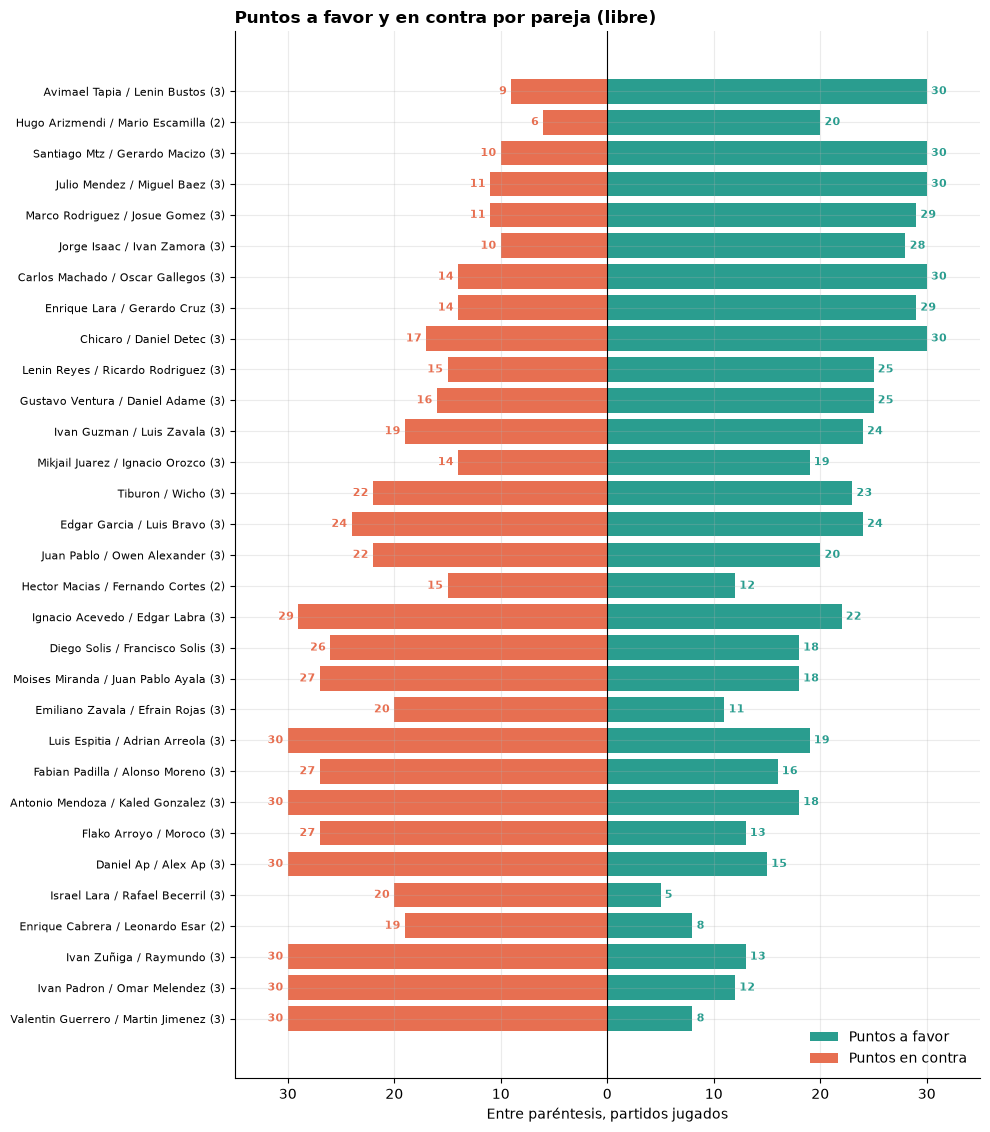

### Un torneo único

Los 8 grupos terminaron con la estructura más limpia posible: el primero ganó 3 partidos, el segundo 2, el tercero 1 y el último ninguno. Ni una sorpresa circular ni un solo empate en victorias. Si cada partido se hubiera decidido al azar, que los 8 grupos salieran así pasaría una vez de cada 1,300. Un torneo único, casi un milagro probabilístico.

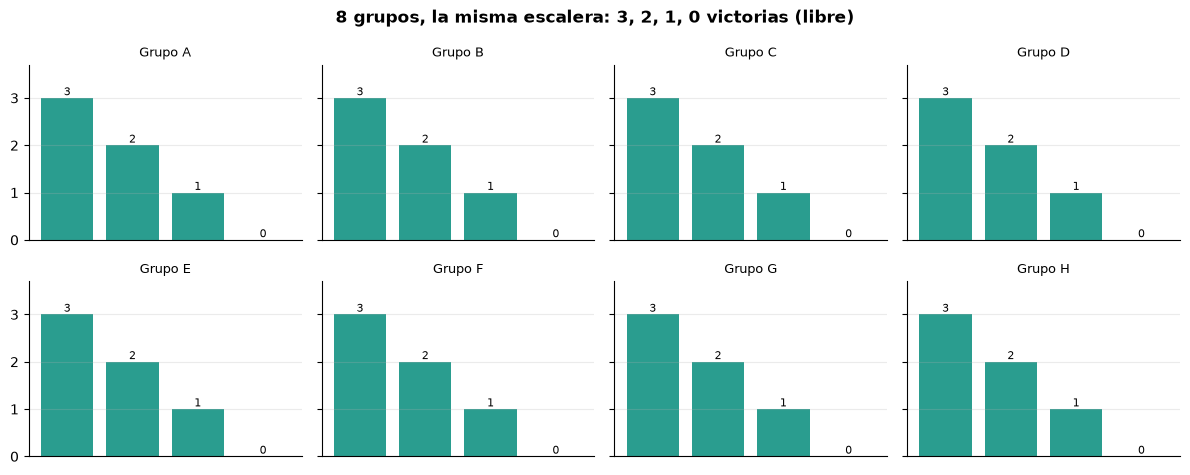

### Quien anota, defiende

Las parejas que más puntos anotaron por partido tendieron a ser las que menos recibieron (correlación de -0.75). En este torneo, atacar bien y defender bien fueron casi lo mismo.

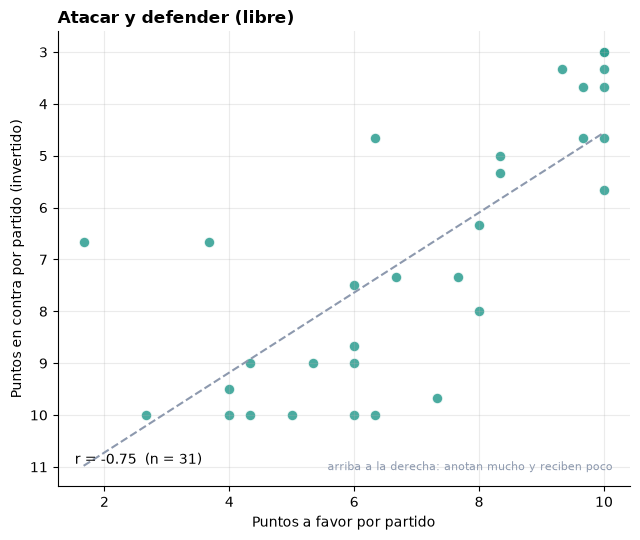

### Empate en la cima

Una pareja que ganara todos sus partidos 10-0 tendría 100% de sinergia. En la cima hubo un empate: Avimael Tapia / Lenin Bustos y Hugo Arizmendi / Mario Escamilla, con 72.7% cada una. El promedio fue 9.1%.

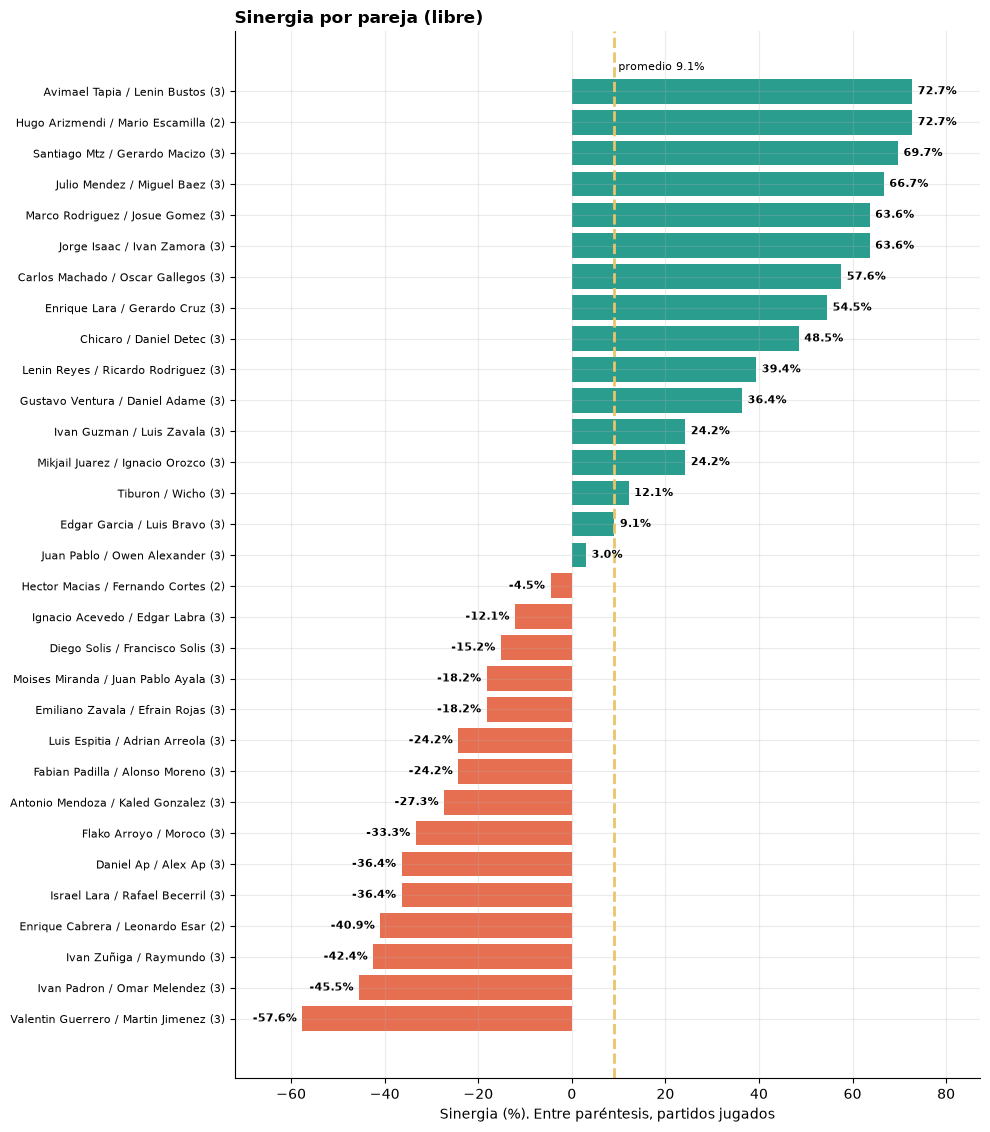

### 6 parejas siempre llegaron a 10

Ganaron todos sus partidos llegando siempre a 10 puntos. Para desempatar, cuenta quién dejó menos puntos al rival: Avimael Tapia / Lenin Bustos (3 partidos) y Hugo Arizmendi / Mario Escamilla (2 partidos), con 3.0 por partido.

### Ganar no es dominar

Jorge Isaac / Ivan Zamora ganaron 2 partidos y Chicaro / Daniel Detec ganaron 3, pero Jorge Isaac / Ivan Zamora tuvieron más sinergia (63.6% contra 48.5%). Importa cuánto ganas, no solo cuántas veces.

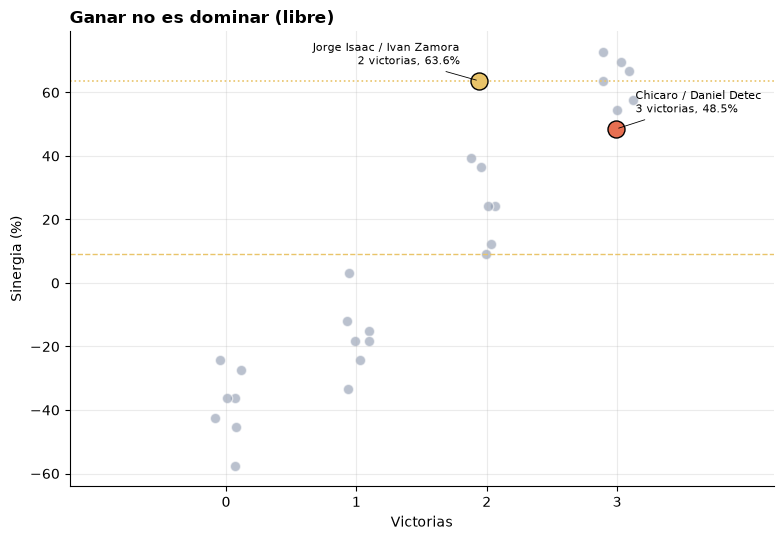

### Partidos de infarto

5 de 45 partidos se resolvieron por 2 puntos o menos. El más apretado: Edgar Garcia / Luis Bravo 8-7 Juan Pablo / Owen Alexander. Se acabó el tiempo antes de que alguien llegara a 10.

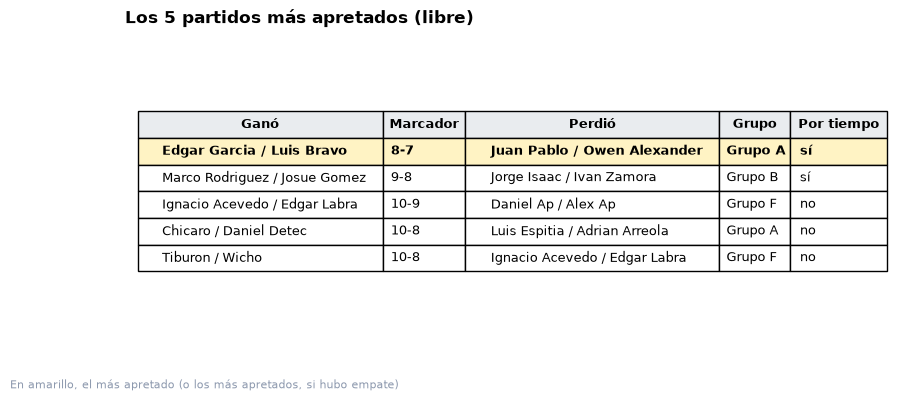

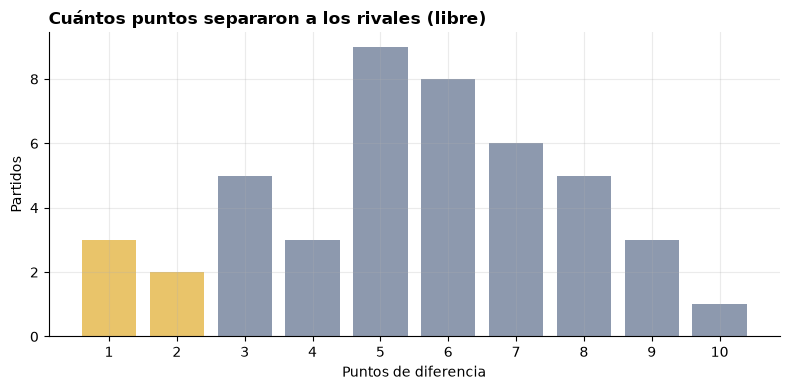

### El partido menos parejo del torneo

El partido menos parejo del torneo terminó 10-0: Jorge Isaac / Ivan Zamora contra Valentin Guerrero / Martin Jimenez. Fue el único 10-0 de toda la fase de grupos.

### La pareja de los extremos

Jorge Isaac / Ivan Zamora ganaron 10-0 en uno de sus partidos y perdieron 8-9 contra Marco Rodriguez / Josue Gomez. Un punto los separó de terminar invictos.

### El partido de la distancia

El partido con más kilómetros de por medio: Diego Solis / Francisco Solis contra Enrique Lara / Gerardo Cruz. En promedio, 358 km separaban a sus ciudades de origen. Terminó 10-3 a favor de Enrique Lara / Gerardo Cruz. Y 3 de 45 partidos fueron entre parejas de la misma ciudad.

In [69]:
mostrar("libre")

## Masters

### 10 parejas, un solo torneo

Llegaron de 3 ciudades distintas, jugaron 8 partidos y entre todos anotaron más de 120 puntos. Esta es su historia.

### De dónde vinieron

Los 20 jugadores salieron de 3 ciudades de Guanajuato, y Irapuato puso 11. Cada punto en el mapa es una ciudad que mandó jugadores a la cancha.

### Cada punto cuenta

Cada barra es una pareja: a la derecha, lo que anotó; a la izquierda, lo que recibió. Entre más larga la derecha y más corta la izquierda, más cerca de la perfección.

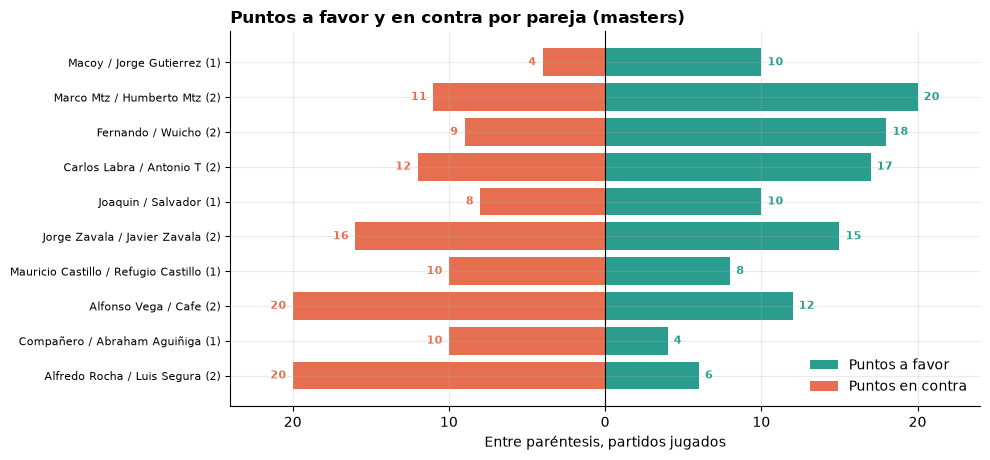

### Cada grupo tuvo su orden

En los 4 grupos hubo un primero, un segundo y un tercero: 2 victorias, 1 y 0. Nadie rompió el orden.

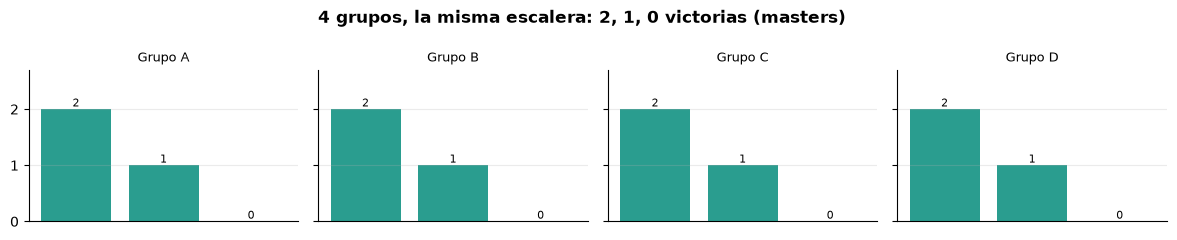

### Quien anota, defiende

Las parejas que más puntos anotaron por partido tendieron a ser las que menos recibieron (correlación de -0.75). En este torneo, atacar bien y defender bien fueron casi lo mismo.

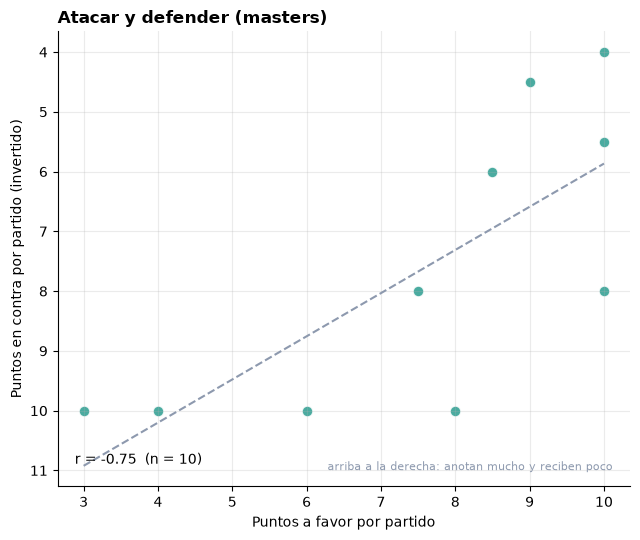

### La sinergia más cercana a la perfección

Una pareja que ganara todos sus partidos 10-0 tendría 100% de sinergia. La más cercana fue Macoy / Jorge Gutierrez: 10 puntos a favor, 4 en contra y 63.6%. Lo logró en un solo partido. El promedio fue 9.1%.

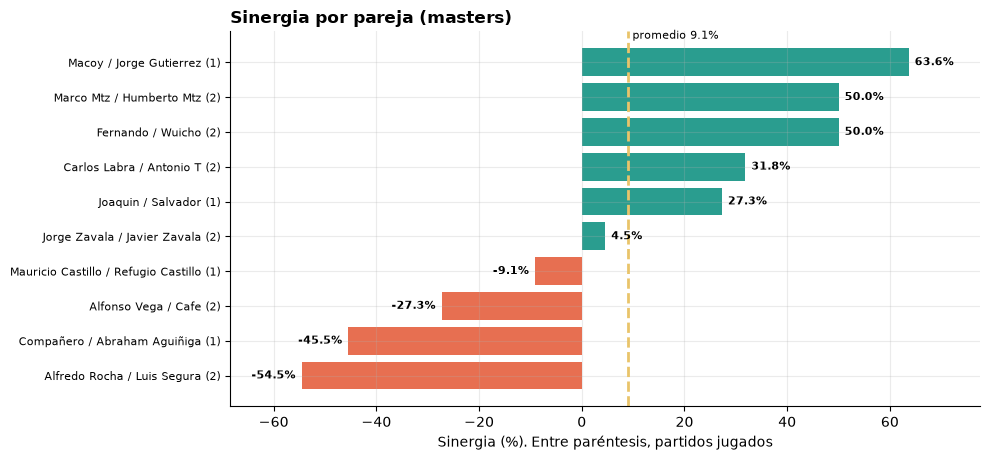

### 3 parejas siempre llegaron a 10

Ganaron todos sus partidos llegando siempre a 10 puntos. Para desempatar, cuenta quién dejó menos puntos al rival: Macoy / Jorge Gutierrez (1 partido), con 4.0 por partido.

### Partidos de infarto

2 de 8 partidos se resolvieron por 2 puntos o menos. Hubo empate en el más apretado: Joaquin / Salvador 10-8 Mauricio Castillo / Refugio Castillo y Jorge Zavala / Javier Zavala 10-8 Alfonso Vega / Cafe.

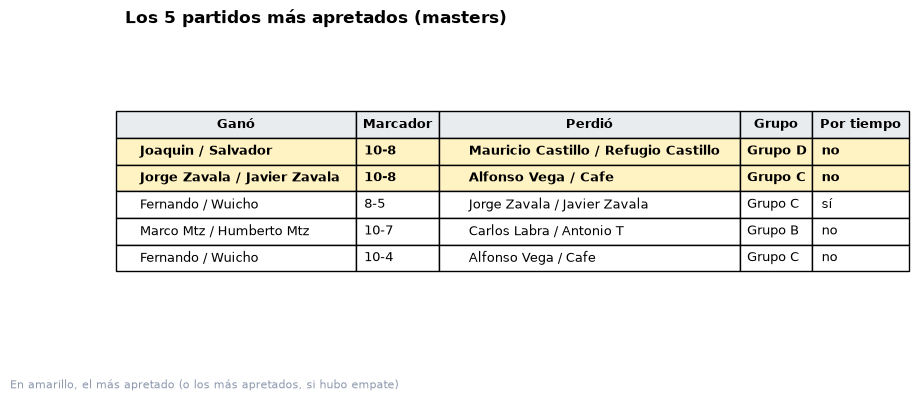

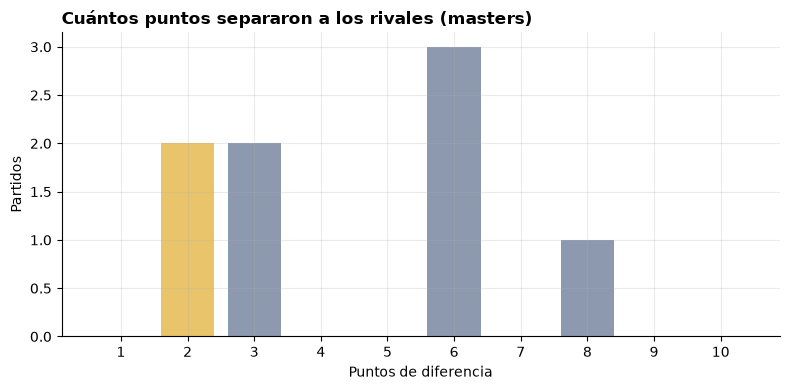

### El partido menos parejo del torneo

El partido menos parejo del torneo terminó 10-2: Carlos Labra / Antonio T contra Alfredo Rocha / Luis Segura.

### Entre vecinos

4 de 8 partidos fueron entre parejas de la misma ciudad. El que más kilómetros juntó apenas llegó a 63 km de distancia promedio.

In [70]:
mostrar("masters")

**Celda 27: K-Means**